0        5
1        5
2        5
3        4
4        3
        ..
20635    2
20636    2
20637    2
20638    2
20639    2
Name: income_cat, Length: 20640, dtype: category
Categories (5, int64): [1 < 2 < 3 < 4 < 5]


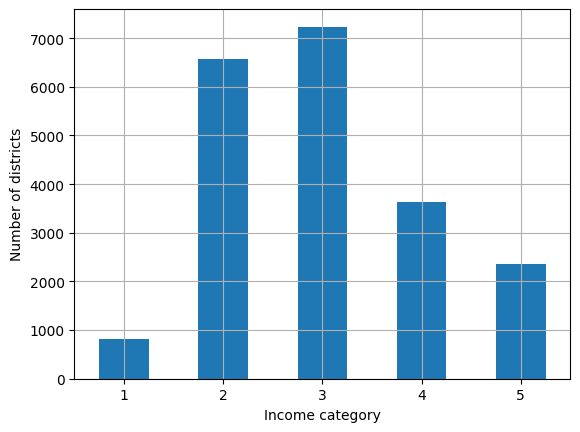

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

housing = pd.read_csv('/home/siyam/MyCodes/MachineLearning/Book/datasets/housing/housing.csv')

from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)


housing["income_cat"] = pd.cut(housing["median_income"],
                        bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                        labels=[1, 2, 3, 4, 5])

print(housing["income_cat"])

housing["income_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Income category")
plt.ylabel("Number of districts")

from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=.2, random_state=42)

In [2]:
from sklearn.model_selection import StratifiedShuffleSplit
splitter = StratifiedShuffleSplit(n_splits=10,test_size=0.2,random_state=42)

# strat_splits = []

# for trainidx, testidx in splitter.split(housing, housing['income_cat']):
#     strat_trn = housing.iloc[trainidx]
#     strat_tst = housing.iloc[testidx]
#     strat_splits.append([strat_trn, strat_tst])

# for i, (train,test) in enumerate(strat_splits):
#     print(f"Split {i+1}:")
#     print("Train: ", train.shape)
#     print("Test : ", test.shape)
#     print()

strat_train_set, strat_test_set = train_test_split(housing, test_size=0.2, 
                                                   stratify=housing['income_cat'], 
                                                   random_state=42)

print(strat_test_set)

for x in (strat_train_set, strat_test_set):
    x.drop('income_cat', axis=1, inplace=True)

print(strat_test_set)


       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
3905     -121.95     37.11                21.0       2387.0           357.0   
16821    -118.01     33.89                36.0       1589.0           265.0   
2900     -118.18     33.74                30.0       5915.0          1750.0   
7193     -122.48     37.74                52.0       2166.0           423.0   
13928    -122.39     37.78                 5.0       1405.0           515.0   
...          ...       ...                 ...          ...             ...   
12369    -124.16     40.79                46.0       3042.0           597.0   
8707     -119.01     35.39                29.0       1820.0           459.0   
16634    -123.01     38.67                33.0        914.0           147.0   
9779     -122.03     37.60                24.0       2077.0           383.0   
3455     -117.12     32.74                52.0       1969.0           389.0   

       population  households  median_income  media

<Axes: xlabel='longitude', ylabel='latitude'>

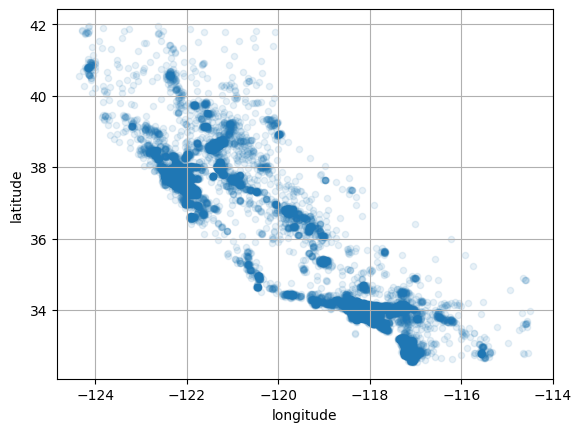

In [3]:
housing = strat_train_set.copy()

housing.plot(kind='scatter', x='longitude', y= 'latitude', grid= 'True', alpha=.1)

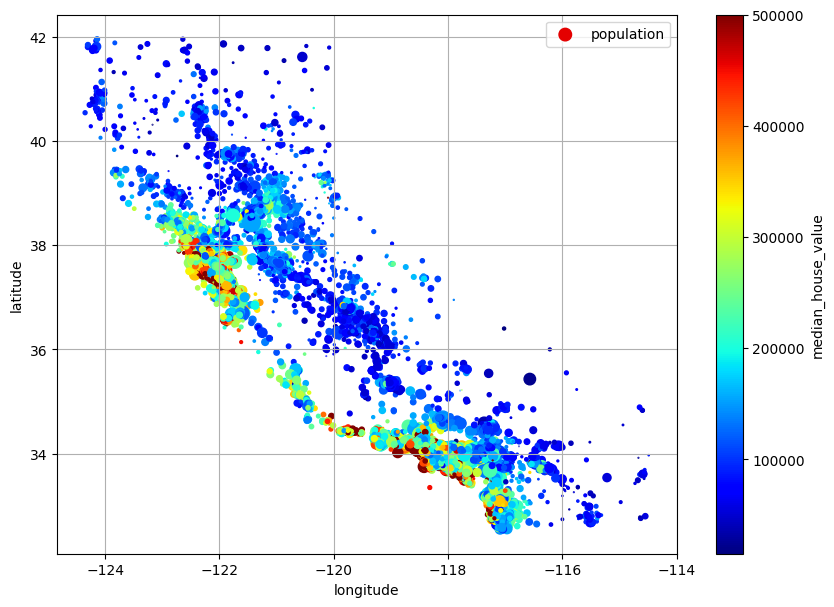

In [4]:
housing.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    grid=True,
    s=housing["population"] / 100,
    label="population",
    c="median_house_value",
    cmap="jet",
    colorbar=True,
    legend=True,
    sharex=False,
    figsize=(10, 7)
)
plt.show()

In [5]:
correlation_matrix = housing.corr(numeric_only=True)
correlation_matrix["median_house_value"].sort_values(ascending=False)

print(housing.info())

<class 'pandas.DataFrame'>
Index: 16512 entries, 13096 to 19888
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           16512 non-null  float64
 1   latitude            16512 non-null  float64
 2   housing_median_age  16512 non-null  float64
 3   total_rooms         16512 non-null  float64
 4   total_bedrooms      16344 non-null  float64
 5   population          16512 non-null  float64
 6   households          16512 non-null  float64
 7   median_income       16512 non-null  float64
 8   median_house_value  16512 non-null  float64
 9   ocean_proximity     16512 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.4 MB
None


# Heatmap

<Axes: >

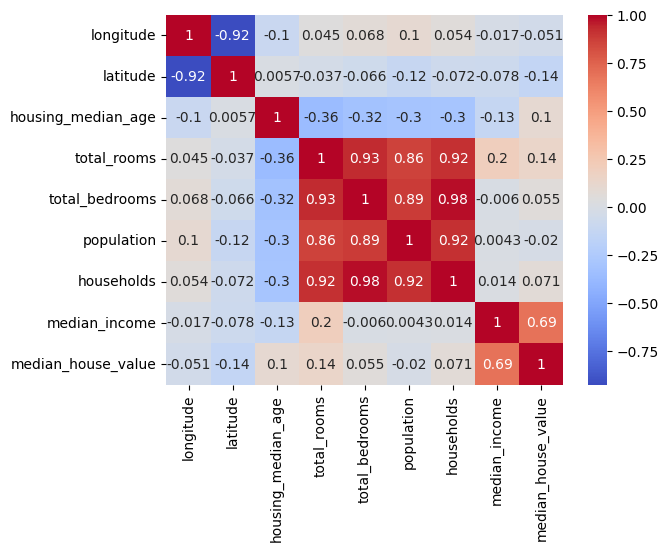

In [6]:
import seaborn as sns
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=True)

array([[<Axes: xlabel='median_house_value', ylabel='median_house_value'>,
        <Axes: xlabel='housing_median_age', ylabel='median_house_value'>,
        <Axes: xlabel='total_rooms', ylabel='median_house_value'>,
        <Axes: xlabel='median_income', ylabel='median_house_value'>],
       [<Axes: xlabel='median_house_value', ylabel='housing_median_age'>,
        <Axes: xlabel='housing_median_age', ylabel='housing_median_age'>,
        <Axes: xlabel='total_rooms', ylabel='housing_median_age'>,
        <Axes: xlabel='median_income', ylabel='housing_median_age'>],
       [<Axes: xlabel='median_house_value', ylabel='total_rooms'>,
        <Axes: xlabel='housing_median_age', ylabel='total_rooms'>,
        <Axes: xlabel='total_rooms', ylabel='total_rooms'>,
        <Axes: xlabel='median_income', ylabel='total_rooms'>],
       [<Axes: xlabel='median_house_value', ylabel='median_income'>,
        <Axes: xlabel='housing_median_age', ylabel='median_income'>,
        <Axes: xlabel='total_rooms'

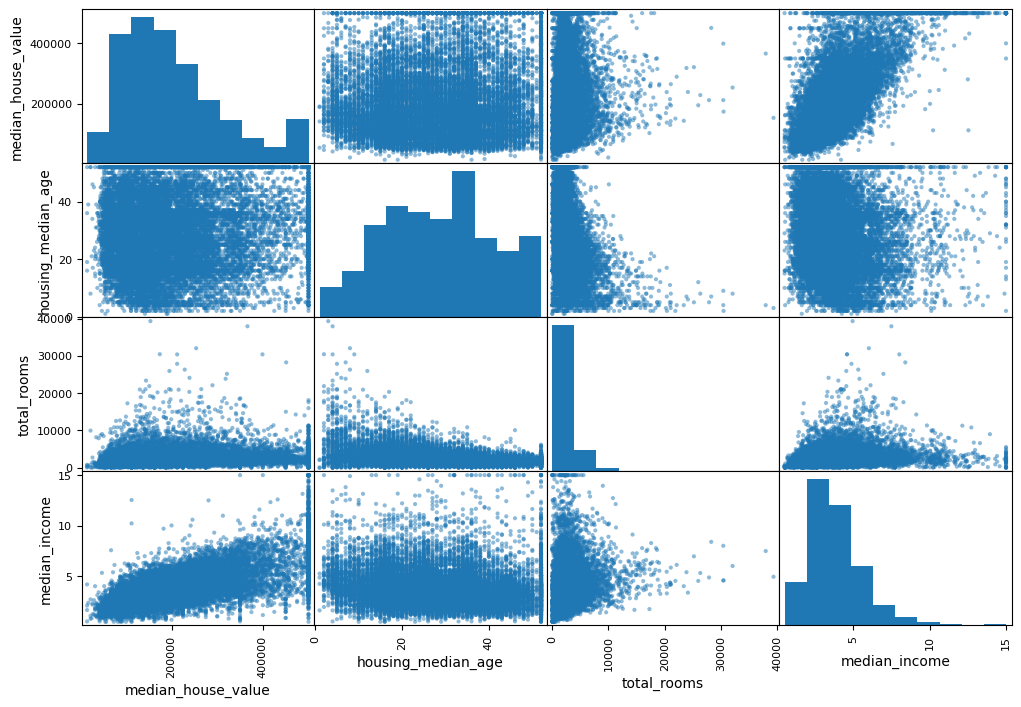

In [7]:
from pandas.plotting import scatter_matrix
attributes = ['median_house_value', 'housing_median_age', 'total_rooms', 'median_income']
scatter_matrix(housing[attributes], figsize=(12,8))

<Axes: xlabel='median_income', ylabel='median_house_value'>

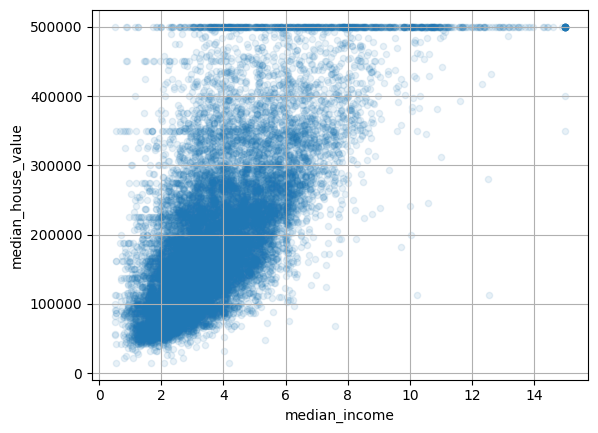

In [8]:
housing.plot(x='median_income',
             y='median_house_value',
             alpha=0.1,
             grid=True,
             kind='scatter')

In [9]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
13096,-122.42,37.80,52.0,3321.0,1115.0,1576.0,1034.0,2.0987,458300.0,NEAR BAY
14973,-118.38,34.14,40.0,1965.0,354.0,666.0,357.0,6.0876,483800.0,<1H OCEAN
3785,-121.98,38.36,33.0,1083.0,217.0,562.0,203.0,2.4330,101700.0,INLAND
14689,-117.11,33.75,17.0,4174.0,851.0,1845.0,780.0,2.2618,96100.0,INLAND
20507,-118.15,33.77,36.0,4366.0,1211.0,1912.0,1172.0,3.5292,361800.0,NEAR OCEAN


In [10]:
housing['rooms_per_house'] = housing['total_rooms'] / housing['households']
housing['bedrooms_ratio']  = housing['total_bedrooms'] / housing['total_rooms']
housing['people_per_house']= housing['population'] / housing['households']

In [11]:
corr_matrix = housing.corr(numeric_only=True)
print(corr_matrix)

                    longitude  latitude  housing_median_age  total_rooms  \
longitude            1.000000 -0.924213           -0.102937     0.044558   
latitude            -0.924213  1.000000            0.005692    -0.036753   
housing_median_age  -0.102937  0.005692            1.000000    -0.361710   
total_rooms          0.044558 -0.036753           -0.361710     1.000000   
total_bedrooms       0.068210 -0.066391           -0.317978     0.930076   
population           0.104236 -0.115677           -0.301906     0.863967   
households           0.054261 -0.071604           -0.300075     0.916143   
median_income       -0.016542 -0.078137           -0.127043     0.197720   
median_house_value  -0.050859 -0.139584            0.102175     0.137455   
rooms_per_house     -0.027899  0.108037           -0.153900     0.128631   
bedrooms_ratio       0.087802 -0.108871            0.139119    -0.183273   
people_per_house     0.024587 -0.026457            0.012771    -0.037702   

           

In [12]:
housing = strat_train_set.drop("median_house_value", axis=1)
housing_labels = strat_train_set["median_house_value"].copy()

## Removing whole row where there is missing value

In [13]:
# median=housing["total_bedrooms"].median()
# housing['total_bedrooms'] = housing['total_bedrooms'].fillna(median)

# Imputer

In [14]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')

housing_num = housing.select_dtypes(include=np.number)
# print(housing_num.info())
imputer.fit(housing_num)
print(imputer.statistics_)
print(housing_num.median().values)

X = imputer.transform(housing_num)

print('Number of NaN inside housing_num :\n',np.isnan(housing_num).sum())
print('Number of NaN inside X :',np.isnan(X).sum())

[-118.51     34.26     29.     2125.      434.     1167.      408.
    3.5385]
[-118.51     34.26     29.     2125.      434.     1167.      408.
    3.5385]
Number of NaN inside housing_num :
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        168
population              0
households              0
median_income           0
dtype: int64
Number of NaN inside X : 0


# RBF 

In [15]:
from sklearn.metrics.pairwise import rbf_kernel

age_simil_35 = rbf_kernel(
    housing[['housing_median_age']],
    [[35]], 
    gamma=0.1
)


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
model = LinearRegression()
target_scaler = StandardScaler()

scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

model.fit(housing[['median_income']], scaled_labels)

new_data = np.array([[25000.0], [22000.0], [23000.0], [21000.0]], dtype=float)

scaled_predictions = model.predict(new_data)

predictions = target_scaler.inverse_transform(scaled_predictions)
print(predictions)


[[1.04896849e+09]
 [9.23097547e+08]
 [9.65054529e+08]
 [8.81140565e+08]]


/home/siyam/MyCodes/MachineLearning/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Transformed Target Regressor

In [17]:
from sklearn.compose import TransformedTargetRegressor

TTRmodel = TransformedTargetRegressor(regressor=LinearRegression(), transformer=StandardScaler())

TTRmodel.fit(
    housing[['median_income']],
    housing_labels
)

new_data = pd.DataFrame(
    new_data,
    columns=['median_income']
)

TTRpred = TTRmodel.predict(new_data)
print(TTRpred)

[1.04896849e+09 9.23097547e+08 9.65054529e+08 8.81140565e+08]


# Custom Transformer

In [18]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(
    func=np.log,
    inverse_func=np.exp
)


# RBF using Function Transformer

for 1 Feature

In [19]:
rbf_transformer = FunctionTransformer(
    func=rbf_kernel,
    kw_args=dict(   
        Y=[[35.0]], # y= reference point, like 35 theke koto kom/beshi
        gamma=0.1
    )
)
""" *args → arguments → positional arguments
**kwargs → keyword arguments → নাম দিয়ে দেওয়া arguments """
age_simil_35 = rbf_transformer.transform(housing[['housing_median_age']])


For 2 Features

In [20]:
san_francisco_coords = 37.7749, -122.41

san_francisco_transformer = FunctionTransformer(
    func=rbf_kernel,
    kw_args= dict(
        Y=[san_francisco_coords],
        gamma=0.1
    )
)

similarity_to_sf = san_francisco_transformer.transform(housing[['latitude', 'longitude']])

similarity_to_sf

array([[0.999927  ],
       [0.05258419],
       [0.94864161],
       ...,
       [0.00388525],
       [0.05038518],
       [0.99868067]], shape=(16512, 1))

In [21]:
print(X.shape)

(16512, 8)


# Custom Transformer

In [22]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StandardScalerClone(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True):
        self.with_mean = with_mean
        
    def fit(self,X, y=None):
        X = check_array(X)
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.n_features_in_ = X.shape[1]
        return self
    
    def transform(self,X):
        check_is_fitted(self)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        
        if self.with_mean:
            X -= self.mean_
            return X / self.scale_ # standardization = (X - u) / sigma
        

In [23]:
x = 5
assert x == 5

# Cluster Clone

[[0.   0.98 0.   0.   0.   0.   0.13 0.55 0.   0.56]
 [0.64 0.   0.11 0.04 0.   0.   0.   0.   0.99 0.  ]
 [0.   0.65 0.   0.   0.01 0.   0.49 0.59 0.   0.28]]


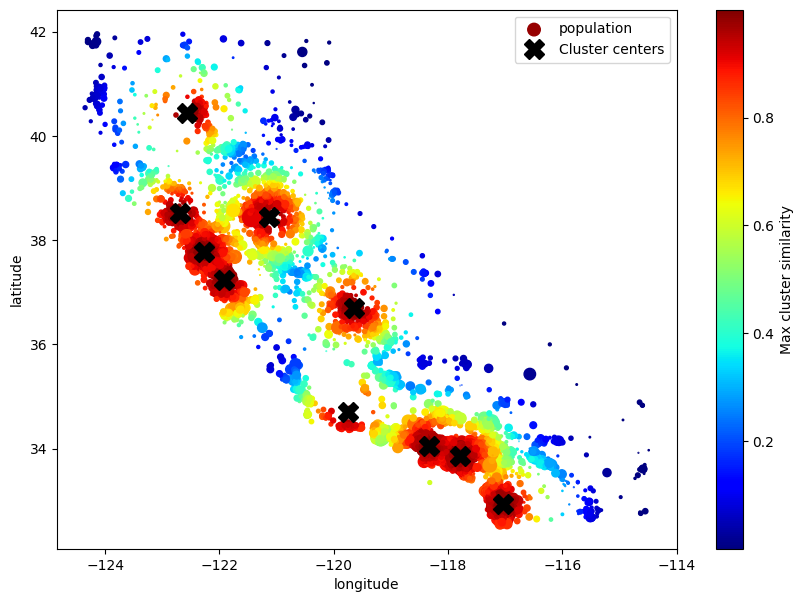

In [24]:
from sklearn.cluster import KMeans

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state
        
    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(
            self.n_clusters, random_state=self.random_state
        )
        self.kmeans_.fit(X,sample_weight=sample_weight)
        return self
    
    def transform(self,X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)
    
    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(1,self.n_clusters+1)]
        


cluster_sim = ClusterSimilarity(
    n_clusters=10,
    gamma=1.0,
    random_state=42
)

similarities = cluster_sim.fit_transform(housing[['latitude', 'longitude']], 
                                         sample_weight=housing_labels)

print(similarities[:3].round(2))

housing["Max cluster similarity"] = similarities.max(axis=1)

housing.plot(
    kind="scatter", x="longitude", y="latitude",
    s=housing["population"] / 100, label="population",
    c="Max cluster similarity",
    figsize=(10, 7),
    legend=True,
    cmap="jet",
    colorbar=True,
    sharex=False
)

plt.plot(cluster_sim.kmeans_.cluster_centers_[:, 1],
         cluster_sim.kmeans_.cluster_centers_[:, 0],
         linestyle="", color="black", marker="X", markersize=15,
         label="Cluster centers")

plt.legend(loc="upper right")
plt.show()

# Transformation Pipelines

In [25]:
import sklearn
from sklearn.pipeline import Pipeline
sklearn.set_config(display="diagram")
num_pipeline = Pipeline([
("impute", SimpleImputer(strategy="median")),
("standardize", StandardScaler()),
])

# num_pipeline
housing_num_prepared = num_pipeline.fit_transform(housing_num)
print(housing_num_prepared[:2].round(2))

df_housing_num_prepared = pd.DataFrame(
housing_num_prepared,
columns=num_pipeline.get_feature_names_out(),
index=housing_num.index)

# print(df_housing_num_prepared)
print(num_pipeline[1])
num_pipeline[1] 

[[-1.42  1.01  1.86  0.31  1.37  0.14  1.39 -0.94]
 [ 0.6  -0.7   0.91 -0.31 -0.44 -0.69 -0.37  1.17]]
StandardScaler()


,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# আমাদের ধরে নেওয়া dataset-এর columns:
# age, income, city, gender

# =========================================================
# 1. "drop" → column বাদ দেওয়া
# =========================================================

preprocessing_drop = ColumnTransformer([
    # age এবং income → StandardScaler দিয়ে scale হবে
    ("num", StandardScaler(), ["age", "income"]),

    # city → পুরোপুরি বাদ যাবে
    ("cat", "drop", ["city"])
])


# =========================================================
# 2. "passthrough" → column কোনো পরিবর্তন ছাড়াই রাখা
# =========================================================

preprocessing_passthrough = ColumnTransformer([
    # age এবং income → StandardScaler দিয়ে scale হবে
    ("num", StandardScaler(), ["age", "income"]),

    # city → কোনো transformation হবে না
    # যেমন আছে তেমনই থাকবে
    ("cat", "passthrough", ["city"])
])


# =========================================================
# 3. remainder="drop" → যেসব column list করা হয়নি,
#    সেগুলো default হিসেবে বাদ যাবে
# =========================================================

preprocessing_remainder_drop = ColumnTransformer(
    [
    # age এবং income → StandardScaler
    ("num", StandardScaler(), ["age", "income"]),

    # city → OneHotEncoder
    ("cat", OneHotEncoder(), ["city"])

    # gender এখানে দেওয়া হয়নি
    # তাই defaultভাবে gender বাদ যাবে
    ]
)


# =========================================================
# 4. remainder="passthrough" → যেসব column list করা হয়নি,
#    সেগুলো unchanged অবস্থায় থাকবে
# =========================================================

preprocessing_remainder_pass = ColumnTransformer(
    [
        # age এবং income → StandardScaler
        ("num", StandardScaler(), ["age", "income"]),

        # city → OneHotEncoder
        ("cat", OneHotEncoder(), ["city"])
    ],

    # gender-এর মতো unlisted columns unchanged থাকবে
    remainder="passthrough"
)


# =========================================================
# 5. remainder-এ transformer দেওয়া
# =========================================================

preprocessing_remainder_transformer = ColumnTransformer(
    [
        # age এবং income → StandardScaler
        ("num", StandardScaler(), ["age", "income"]),

        # city → OneHotEncoder
        ("cat", OneHotEncoder(), ["city"])
    ],

    # list করা হয়নি এমন columns-গুলোর ওপরও
    # StandardScaler() প্রয়োগ হবে
    remainder=StandardScaler()
)

# Complete Pre-processing Pipeline

In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_selector
def column_ratio(X):
    return X[:,[0]] / X[:,[1]]

def ratio_name(function_transformer, feature_names_in):
    return ['ratio']

def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy='median'),
        FunctionTransformer(
            column_ratio, feature_names_out=ratio_name
        ),
        StandardScaler()
    )
    
log_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    FunctionTransformer(
        np.log, feature_names_out='one-to-one'
    ),
    StandardScaler()
)

cat_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore')
)

cluster_simil = ClusterSimilarity(
    n_clusters=10,
    gamma=1.0,
    random_state=42
)

default_num_pipeline = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler()
)

preprocessing = ColumnTransformer(
    [
        ('bedrooms_per_house', ratio_pipeline(), ['total_bedrooms', 'total_rooms']),
        ('rooms_per_house', ratio_pipeline(), ['total_rooms', 'households']),
        ("log", log_pipeline, ["total_bedrooms", "total_rooms",
                                "population","households", "median_income"]),
        ("geo", cluster_simil, ["latitude", "longitude"]),
        ("cat", cat_pipeline, make_column_selector(dtype_include=object))
    ],
    remainder = default_num_pipeline
)

# Using the pipeline

In [28]:
housing_prepared = preprocessing.fit_transform(housing)
print(housing_prepared.shape)
print(preprocessing.get_feature_names_out)


(16512, 24)
<bound method ColumnTransformer.get_feature_names_out of ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                             SimpleImputer(strategy='median')),
                                            ('standardscaler',
                                             StandardScaler())]),
                  transformers=[('bedrooms_per_house',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('functiontransformer',
                                                  FunctionTransformer(feature_names_out=<function ratio_name at 0x7f46658bdc70>,
                                                                      func=<function co...
                                 ['total_bedrooms', 'total_rooms', 'population',
                                  'households', 'median_income']),
            

# Training a model

Linear Regression

In [29]:
from sklearn.linear_model import LinearRegression
lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(housing, housing_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bedrooms_per_house', ...), ('rooms_per_house', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",Pipeline(step...ardScaler())])
,"sparse_threshold sparse_thr

Predictions

In [30]:
housing_predictions = lin_reg.predict(housing)
print(housing_predictions.round(2))

[243793.69 372334.81 108945.27 ... 198005.93 309168.73 251025.74]


Performance metrics using RMSE

In [31]:
from sklearn.metrics import root_mean_squared_error

lin_mse = root_mean_squared_error(housing_labels, housing_predictions)
lin_mse

68679.39744902379

Decision Tree Regressor

In [32]:
from sklearn.tree import DecisionTreeRegressor
tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_reg.fit(housing, housing_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('bedrooms_per_house', ...), ('rooms_per_house', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",Pipeline(step...ardScaler())])
,"sparse_threshold spars

In [33]:
tree_reg_predictions = tree_reg.predict(housing)
tree_reg_rmse = root_mean_squared_error(housing_labels, tree_reg_predictions)
tree_reg_rmse

0.0

# Better Evaluation Using Cross-Validation

In [34]:
from sklearn.model_selection import cross_val_score

tree_rmses = -cross_val_score(tree_reg, housing, housing_labels, cv=10, scoring='neg_root_mean_squared_error')
pd.Series(tree_rmses).describe().round(2)

count       10.00
mean     66602.02
std       2379.47
min      62864.75
25%      65135.96
50%      66658.21
75%      67734.84
max      70628.52
dtype: float64

# Using Random Forest Regressor

In [35]:
from sklearn.ensemble import RandomForestRegressor
import os
import joblib

forest_reg = make_pipeline(preprocessing, RandomForestRegressor(n_jobs=-1,random_state=42))

forest_reg_path = 'models/forest_reg.pkl'

if os.path.exists(forest_reg_path):
    print('loading model...')
    forest_reg = joblib.load(forest_reg_path)
else:
    print('training random forest model')
    forest_rmses = -cross_val_score(forest_reg, housing, housing_labels, cv=10, scoring='neg_root_mean_squared_error')
    print("RMSE scores:", forest_rmses)
    print("Mean RMSE:", forest_rmses.mean())
    print("Std:", forest_rmses.std())
    
    forest_reg.fit(housing, housing_labels)
    os.makedirs('models', exist_ok=True)
    joblib.dump(forest_reg, forest_reg_path)
    print('Model Saved')


loading model...


# Fine Tuning Model

### ==> Grid Search

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
import joblib
import os

full_pipeline = Pipeline([
    ('preprocessing', preprocessing),
    ('random_forest', RandomForestRegressor(random_state=42))
])

param_grid = [
    {
        'preprocessing__geo__n_clusters': [5,8,10],
        'random_forest__max_features': [4,6,8]
    },
    
    {
        'preprocessing__geo__n_clusters': [10,15],
        'random_forest__max_features': [6,8,10]
    }
] # Double underscore __ দিয়ে pipeline-এর ভিতরের step-এ ঢোকা হয়।

model_path = 'models/grid_search.pkl'

if os.path.exists(model_path):
    print('Loading saved model...')
    grid_search = joblib.load(model_path)
else:
    print("Training model...")
    grid_search = GridSearchCV(full_pipeline, param_grid, cv=3, n_jobs=-1, scoring='neg_root_mean_squared_error')
    grid_search.fit(housing, housing_labels)
    os.makedirs("models", exist_ok=True)
    joblib.dump(grid_search, model_path)
    
    print("Model has been saved")


Loading saved model...


In [38]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False,
inplace=True)

cv_res[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].head()

,params,mean_test_score,std_test_score,rank_test_score
12,"{'preprocessing__geo__n_clusters': 15, 'random...",-44931.189504,386.180717,1
13,"{'preprocessing__geo__n_clusters': 15, 'random...",-44936.189140,612.942032,2
14,"{'preprocessing__geo__n_clusters': 15, 'random...",-45312.537458,237.478877,3
7,"{'preprocessing__geo__n_clusters': 10, 'random...",-45722.594579,505.650279,4
9,"{'preprocessing__geo__n_clusters': 10, 'random...",-45722.594579,505.650279,4


### ==> Randomized Search